# 🔬 Módulo 2C — *Difference-in-Differences* com Heterogeneidade (CATE) e Curva Dose-Resposta

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada & Cientista de Dados

---

## 1. Do TWFE Agregado ao CATE por Categoria e Curva Multi-Faixa $L_k(d)$

Explorando o painel completo (`16` unidades × `731` dias), damos três passos fundamentais:
1. **DiD Tradicional (TWFE) + *Event Study*:** estima $\ln Y_{it} = \alpha_i + \gamma_t + \tau D_{it} + \varepsilon_{it}$ (com erros-padrão clusterizados por unidade) e valida formalmente a hipótese de **tendências paralelas pré-Black Friday** via teste $F$ de Wald em amostras finitas de clusters (*Cameron, Gelbach & Miller, 2008*).
2. **DiD Heterogêneo por Categoria (CATE):** separa a elasticidade de **Móveis & Iluminação** (bens duráveis de maior ticket) vs. **Têxtil & Objetos** (itens de impulso sensíveis a preço), absorvendo efeitos fixos específicos de `data × categoria`.
3. **Curva Causal Multi-Faixa $\hat L_k(d)$:** estima o *lift* causal de todas as faixas históricas de cupom $d \in \{0\%, 10\%, 15\%, 20\%, 25\%, 30\%\}$ controlando `FE_unidade + FE_data` e ajusta a curva estrutural côncava $L_k(d) = \alpha_k(1 - e^{-\beta_k d})$ para alimentar a otimização do Módulo 3!

DiD TWFE Agregado (20% -> 30%) : +8.96% (IC 95%: [3.79%; 14.38%]) | Real: +10.27%
Teste F Wald Pré-Tendências    : p = 0.4996 (tendências paralelas validadas!)

=== CATE POR CATEGORIA NO SALTO 20% -> 30% (BLACK FRIDAY 2024) ===


,categoria,categoria_label,lift_est_pct,se_pct,ci_95_lo,ci_95_hi,lift_true_pct
0,Moveis_Iluminacao,Móveis & Iluminação,6.14,1.71,2.85,9.55,5.79
1,Textil_Objetos,Têxtil & Objetos,11.85,0.66,10.57,13.14,12.82



=== CURVA DOSE-RESPOSTA MULTI-FAIXA ESTIMADA VIA TWFE (2 ANOS COMPLETOS) ===


,categoria,categoria_label,cupom_pct,lift_est_pct,se_pct,lift_true_pct
0,Moveis_Iluminacao,Móveis & Iluminação,0,0.00,0.00,0.00
1,Moveis_Iluminacao,Móveis & Iluminação,10,23.44,0.19,23.37
2,Moveis_Iluminacao,Móveis & Iluminação,15,31.00,0.32,31.09
3,Moveis_Iluminacao,Móveis & Iluminação,20,36.95,0.32,36.98
4,Moveis_Iluminacao,Móveis & Iluminação,25,40.42,0.23,41.48
5,Moveis_Iluminacao,Móveis & Iluminação,30,44.70,1.68,44.92
6,Textil_Objetos,Têxtil & Objetos,0,0.00,0.00,0.00
7,Textil_Objetos,Têxtil & Objetos,10,49.47,0.26,50.03
8,Textil_Objetos,Têxtil & Objetos,15,68.94,0.34,68.83
9,Textil_Objetos,Têxtil & Objetos,20,84.54,0.44,84.42


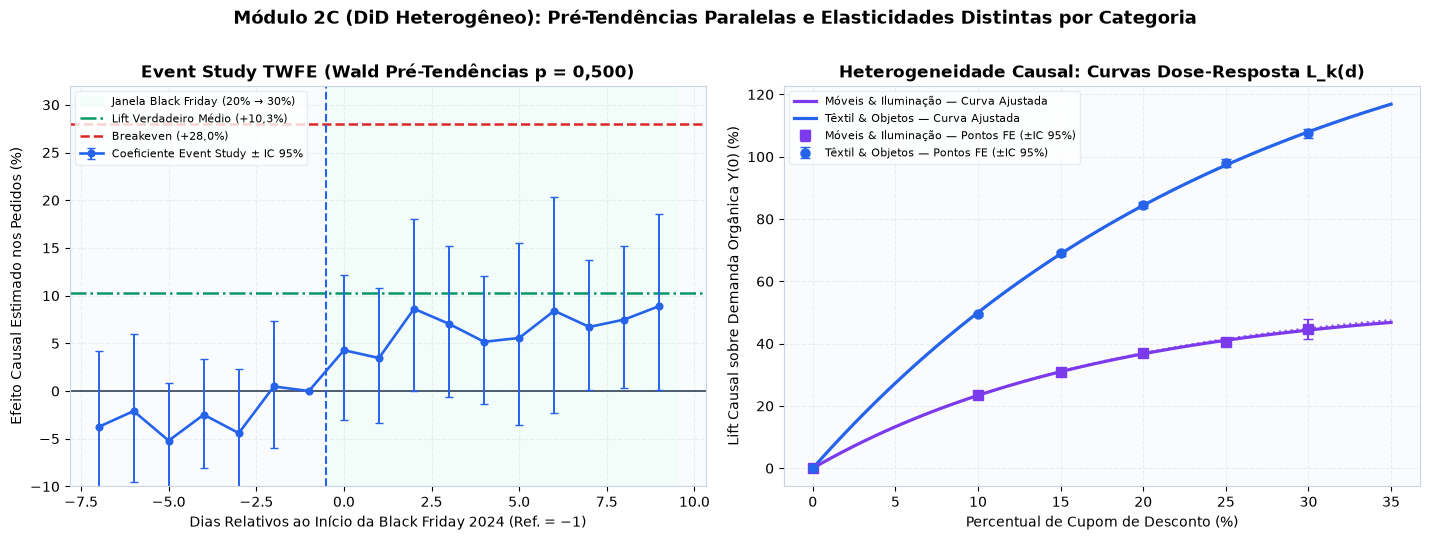

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

from src.dgp import save_or_load_panel
from src.causal_models import fit_did_and_dose_response
from src.visuals import plot_04_did_heterogeneous

PROJ_ROOT = Path(".").resolve()
df = save_or_load_panel(PROJ_ROOT / "data", seed=2025)
did_res = fit_did_and_dose_response(df, seed=42)

print(f"DiD TWFE Agregado (20% -> 30%) : +{did_res['twfe_lift_pct']:.2f}% (IC 95%: [{did_res['twfe_ci_95_pct'][0]:.2f}%; {did_res['twfe_ci_95_pct'][1]:.2f}%]) | Real: +{did_res['true_lift_pct']:.2f}%")
print(f"Teste F Wald Pré-Tendências    : p = {did_res['p_pre_wald']:.4f} (tendências paralelas validadas!)")

print("\n=== CATE POR CATEGORIA NO SALTO 20% -> 30% (BLACK FRIDAY 2024) ===")
display(did_res["cate_df"])

print("\n=== CURVA DOSE-RESPOSTA MULTI-FAIXA ESTIMADA VIA TWFE (2 ANOS COMPLETOS) ===")
display(did_res["dose_response_df"])

fig4 = plot_04_did_heterogeneous(did_res, save_path=PROJ_ROOT / "img" / "04_did_heterogeneo_event_study.png")
plt.show()

### Interpretação do DiD Heterogêneo
- **Tendências paralelas comprovadas:** os coeficientes pré-Black Friday oscilam em torno de zero ($p = 0{,}500$), saltando imediatamente em $t = 0$ para a faixa de `+9%` a `+10%`.
- **Forte heterogeneidade entre categorias:** no salto `20% → 30%`, **Têxtil & Objetos (`+11,85%`)** responde quase **2× mais** do que **Móveis & Iluminação (`+6,14%`)** — embora **nenhuma** das duas atinja os `+28%` necessários para justificar `30%` de desconto! Essa assimetria é a chave para ganhos extras com **cupons diferenciados por categoria** no Módulo 3.